<a href="https://colab.research.google.com/github/MrFrankChen-coder/mr.frankchen/blob/main/Copy_of_%E3%80%8CS7_Lab_CNN_MNIST_ipynb%E3%80%8D%E7%9A%84%E5%89%AF%E6%9C%AC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# S7 Lab · Build a CNN
**AI for Physical Sciences · NTHU · 2 Nov 2026**

You run the lecture's toy CNN by hand, then build a real one in PyTorch, train it on MNIST next to last week's MLP, and look inside it.

| § | what you do |
|---|---|
| 1 | the ring and the cross from the slides: filter, ReLU, max-pool, by hand |
| 2 | MNIST again, now as pictures |
| 3 | build a CNN layer by layer, and train it next to the MLP |
| 4 | look inside: the learned filters, and what they find in one digit |
| 5 | one figure |

- **YOUR TURN** cells: replace each `...` with code. A `check(...)` line after it tells you whether it worked.
- **❓** questions: answer in one or two lines.
- A CPU runtime is enough. MNIST (11 MB) downloads itself the first time, as in S5 and S6.
- **Running locally?** In this folder (it has `pyproject.toml` and `uv.lock`) run once `uv sync` and then `uv run python -m ipykernel install --user --name s7-cnn --display-name "Python (S7 CNN)"`, and choose the kernel **Python (S7 CNN)**. Do not use the Anaconda *base* environment (NumPy 1 vs 2 clash, see S6).
- **On Colab:** nothing to install.

## 0 · Setup (no need to read)

In [1]:
import gzip, math, os, sys, time, urllib.request
import numpy as np, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

SEED = 0
torch.manual_seed(SEED)
torch.set_num_threads(max(1, os.cpu_count() or 1))
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#8e5bd6"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2,
                     "axes.prop_cycle": plt.cycler(color=COLORS)})

def check(name, ok, hint=""):
    print(("✓ " if ok else "✗ ") + name + ("" if ok else f"   ← {hint}"))
print(f"python {sys.version.split()[0]} | numpy {np.__version__} | torch {torch.__version__} | {sys.executable}")

python 3.13.18 | numpy 2.1.3 | torch 2.11.0+cpu | /usr/bin/python3


## 1 · The ring and the cross, by hand
The pictures from the slides: 6 × 6 pixels, 1 = hit, 0 = empty. A ring (think of a Cherenkov ring) and a cross (two crossing tracks).

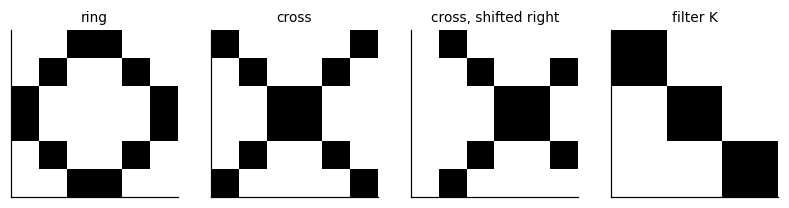

In [2]:
RING = np.array([[0,0,1,1,0,0],
                 [0,1,0,0,1,0],
                 [1,0,0,0,0,1],
                 [1,0,0,0,0,1],
                 [0,1,0,0,1,0],
                 [0,0,1,1,0,0]], float)
CROSS = np.array([[1,0,0,0,0,1],
                  [0,1,0,0,1,0],
                  [0,0,1,1,0,0],
                  [0,0,1,1,0,0],
                  [0,1,0,0,1,0],
                  [1,0,0,0,0,1]], float)

def shift(img, down=0, right=0):
    # move every hit `down` rows and `right` columns; hits that fall off the edge are lost
    out = np.zeros_like(img)
    out[down:, right:] = img[:img.shape[0] - down, :img.shape[1] - right]
    return out

K = np.eye(3)        # the filter from the slides: a 3 x 3 "\" diagonal
B = -2.0             # its bias

fig, axes = plt.subplots(1, 4, figsize=(9, 2.4))
for ax, (title, im) in zip(axes, [("ring", RING), ("cross", CROSS), ("cross, shifted right", shift(CROSS, right=1)), ("filter K", K)]):
    ax.imshow(im, cmap="Greys", vmin=0, vmax=1); ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.show()

**YOUR TURN 1:** write the filter step. Put the 3 × 3 filter on every 3 × 3 patch of the picture, multiply pixel by pixel, add up, and add the bias. A 6 × 6 picture gives a 4 × 4 **feature map**.

**New functions in this cell:**
- `img[i:i+3, j:j+3]` is the 3 × 3 patch whose top-left corner is pixel $(i, j)$ ([NumPy slicing](https://numpy.org/doc/stable/user/basics.indexing.html)).
- `patch * k` multiplies pixel by pixel; [`np.sum`](https://numpy.org/doc/stable/reference/generated/numpy.sum.html) adds up all the entries.
- [`F.conv2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.conv2d.html) is PyTorch's version. It wants 4-D tensors: (pictures, channels, height, width).

In [3]:
def conv2d_valid(img, k, b):
    n_out = img.shape[0] - k.shape[0] + 1          # 6 - 3 + 1 = 4
    out = np.zeros((n_out, n_out))
    # TODO: for every output position (i, j): sum of (3x3 patch of img at (i, j)) * k, plus b
    for i in range(n_out):
        for j in range(n_out):
            patch = img[i:i+3, j:j+3]
            out[i, j] = np.sum(patch * k) + b
    return out

fm = conv2d_valid(CROSS, K, B)
print("feature map of the cross:\n", fm.astype(int))
check("feature map matches the slides", np.array_equal(fm, np.array([[1,-1,-2,-1],[-1,1,-1,-2],[-2,-1,1,-1],[-1,-2,-1,1]])),
      "the top-left entry is 1 + 1 + 1 - 2 = 1")
fm_torch = F.conv2d(torch.tensor(CROSS)[None, None], torch.tensor(K)[None, None], torch.tensor([B], dtype=torch.float64))[0, 0].numpy()
check("PyTorch's conv2d gives the same numbers", np.allclose(fm, fm_torch))

feature map of the cross:
 [[ 1 -1 -2 -1]
 [-1  1 -1 -2]
 [-2 -1  1 -1]
 [-1 -2 -1  1]]
✓ feature map matches the slides
✓ PyTorch's conv2d gives the same numbers


**YOUR TURN 2:** write **max pooling**: cut the 4 × 4 map into four non-overlapping 2 × 2 windows and keep the largest number in each.

In [4]:
def maxpool2x2(x):
    out = np.zeros((x.shape[0] // 2, x.shape[1] // 2))
    # Keep the maximum value in each non-overlapping 2x2 window.
    for i in range(0, x.shape[0], 2):
        for j in range(0, x.shape[1], 2):
            out[i // 2, j // 2] = np.max(x[i:i+2, j:j+2])
    return out

pooled = maxpool2x2(np.maximum(fm, 0))             # ReLU first, then pool
print("pooled:\n", pooled)
check("pooled cross matches the slides", np.array_equal(pooled, np.array([[1., 0.], [0., 1.]])))
check("PyTorch's max_pool2d agrees", np.allclose(pooled, F.max_pool2d(torch.tensor(np.maximum(fm, 0))[None, None], 2)[0, 0].numpy()))

pooled:
 [[1. 0.]
 [0. 1.]]
✓ pooled cross matches the slides
✓ PyTorch's max_pool2d agrees


The rest of the toy CNN from the slides: flatten the four pooled numbers (top-left, top-right, bottom-left, bottom-right), one hidden ReLU node with weights $(1, -0.5, -0.5, 1)$ and bias 0, and two outputs, ring $= 1 - h$ and cross $= h$.

In [5]:
W_H, B_H = np.array([1.0, -0.5, -0.5, 1.0]), 0.0
def toy_cnn(img):
    p = maxpool2x2(np.maximum(conv2d_valid(img, K, B), 0)).reshape(-1)
    h = max(0.0, p @ W_H + B_H)
    return {"pooled": p, "ring": 1 - h, "cross": h}

for name, im in [("ring", RING), ("cross", CROSS), ("cross, shifted right", shift(CROSS, right=1))]:
    r = toy_cnn(im)
    print(f"{name:22s} pooled {r['pooled']}   ring score {r['ring']:5.2f}   cross score {r['cross']:5.2f}")
check("all three match the slides", [toy_cnn(im)["cross"] for im in (RING, CROSS, shift(CROSS, right=1))] == [0.0, 2.0, 1.5])

ring                   pooled [0. 1. 1. 0.]   ring score  1.00   cross score  0.00
cross                  pooled [1. 0. 0. 1.]   ring score -1.00   cross score  2.00
cross, shifted right   pooled [1. 1. 0. 1.]   ring score -0.50   cross score  1.50
✓ all three match the slides


:❓ **Q1.** Now shift the cross **two** pixels to the right. What does the toy CNN say, and why? (Look at the pooled numbers.)

In [6]:
for name, im in [("right 2", shift(CROSS, right=2))]:
    r = toy_cnn(im)
    print(f"{name:18s} pooled {r['pooled']}   ring score {r['ring']:5.2f}   cross score {r['cross']:5.2f}")

right 2            pooled [0. 1. 0. 0.]   ring score  1.00   cross score  0.00


**Your answer:**
經由卷積與最大池化後得到的pooled數值發生改變,進而導致cross score下降，而ring score上升，使模型不再將其判斷為正確的十字

CNN 的隱藏層權重 $W_H = [1.0, -0.5, -0.5, 1.0]$是固定且針對特定位置特徵設計的,當特徵位置因平移而改變時，內積計算與ReLU的結果就會失準，導致模型無法辨識出這是平移後的十字。



## 2 · MNIST, as pictures
The same data as S5 and S6: a random **10k** training subset (seed 0), 5k other training images for **validation**, and the official 10k **test** set.

Last week the MLP saw each digit as a list of 784 numbers. A CNN wants a **picture**, a tensor of shape (digits, channels, height, width) = (N, 1, 28, 28). One channel, because MNIST is grey; a colour picture has 3 (the homework). PyTorch's `.view(-1, 1, 28, 28)` reshapes without copying; `-1` means "work out this size yourself".

train (10000, 1, 28, 28)  val (5000, 1, 28, 28)  test (10000, 1, 28, 28)
✓ pictures of shape (N, 1, 28, 28)


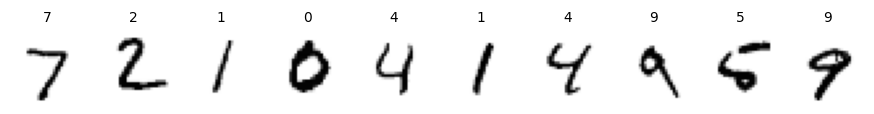

In [7]:
def load_mnist(cache="mnist.npz"):
    # The S5/S6 loader: download once (11 MB) and cache. Pixels are scaled to [0, 1].
    if not os.path.exists(cache):
        base = "https://raw.githubusercontent.com/fgnt/mnist/master/"
        def get(f, offset):
            with urllib.request.urlopen(base + f) as r:
                return np.frombuffer(gzip.decompress(r.read()), np.uint8, offset=offset)
        try:
            d = dict(Xtr=get("train-images-idx3-ubyte.gz", 16).reshape(-1, 784), ytr=get("train-labels-idx1-ubyte.gz", 8),
                     Xte=get("t10k-images-idx3-ubyte.gz", 16).reshape(-1, 784), yte=get("t10k-labels-idx1-ubyte.gz", 8))
        except Exception:
            from sklearn.datasets import fetch_openml
            X, y = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False)
            X, y = X.astype(np.uint8), y.astype(np.uint8)
            d = dict(Xtr=X[:60000], ytr=y[:60000], Xte=X[60000:], yte=y[60000:])
        np.savez_compressed(cache, **d)
    d = np.load(cache)
    return d["Xtr"] / 255.0, d["ytr"], d["Xte"] / 255.0, d["yte"]

X_all, y_all, X_te, y_te = load_mnist()
idx = np.random.default_rng(0).choice(len(X_all), 10_000, replace=False)       # the S5/S6 subset
rest = np.setdiff1d(np.arange(len(X_all)), idx)
idx_val = np.random.default_rng(1).choice(rest, 5_000, replace=False)          # the S6 validation set
T = lambda a, dt=torch.float32: torch.tensor(a, dtype=dt)
X_train, y_train = T(X_all[idx]).view(-1, 1, 28, 28), T(y_all[idx], torch.long)
X_val,   y_val   = T(X_all[idx_val]).view(-1, 1, 28, 28), T(y_all[idx_val], torch.long)
X_test,  y_test  = T(X_te).view(-1, 1, 28, 28), T(y_te, torch.long)
print("train", tuple(X_train.shape), " val", tuple(X_val.shape), " test", tuple(X_test.shape))
check("pictures of shape (N, 1, 28, 28)", X_train.shape[1:] == (1, 28, 28))

fig, axes = plt.subplots(1, 10, figsize=(10, 1.4))
for ax, k in zip(axes, range(10)):
    ax.imshow(X_test[k, 0], cmap="Greys"); ax.set_title(int(y_test[k]), fontsize=9); ax.axis("off")
plt.show()

## 3 · Build a CNN, layer by layer
A CNN is built from the same `nn.Sequential` as last week's MLP, with two new layers:
- [`nn.Conv2d(in_channels, out_channels, kernel_size, padding=1)`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html): `out_channels` filters, each of size `in_channels` × 3 × 3, every one slid over the whole picture: YOUR TURN 1, many times at once. `padding=1` puts a border of zeros around the picture, so 28 × 28 stays 28 × 28 (without it you get 26 × 26, as in §1: 6 → 4).
- [`nn.MaxPool2d(2)`](https://docs.pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html): YOUR TURN 2. It halves the height and the width.

First, one convolution on its own:

In [8]:
torch.manual_seed(0)
conv = nn.Conv2d(1, 8, 3, padding=1)
print("weights", tuple(conv.weight.shape), "  biases", tuple(conv.bias.shape))     # 8 filters of 1 x 3 x 3
x = X_train[:1]                                                                    # one digit, still 4-D
print("one digit", tuple(x.shape), "-> after the convolution", tuple(conv(x).shape),
      "-> after a 2 x 2 max-pool", tuple(F.max_pool2d(conv(x), 2).shape))
print(sum(p.numel() for p in conv.parameters()), "parameters = 8 x (1 x 3 x 3) + 8")

weights (8, 1, 3, 3)   biases (8,)
one digit (1, 1, 28, 28) -> after the convolution (1, 8, 28, 28) -> after a 2 x 2 max-pool (1, 8, 14, 14)
80 parameters = 8 x (1 x 3 x 3) + 8


**YOUR TURN 3:** build the CNN from the slide "A CNN for digits": two blocks of [3 × 3 convolution with `padding=1` → ReLU → 2 × 2 max-pool], with **8** and then **16** filters, then flatten and **one** `nn.Linear` to the 10 outputs (no softmax: `cross_entropy` adds it, as in S6). The shape trace below shows what each layer does to one digit; use it to find the input size of the `nn.Linear`.

**New functions in this cell:**
- [`nn.Conv2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html) and [`nn.MaxPool2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html), as above. The second convolution takes the 8 maps of the first as its 8 input channels.
- [`nn.Flatten()`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Flatten.html) turns (N, channels, height, width) into (N, channels × height × width), the list of numbers an `nn.Linear` wants.

In [9]:
def make_cnn(seed=0):
    torch.manual_seed(seed)
    return nn.Sequential(
        nn.Conv2d(1, 8, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(8, 16, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(16 * 7 * 7, 10),
    )

def n_params(model): return sum(p.numel() for p in model.parameters())

cnn = make_cnn()
x = X_train[:1]
print(f"{'input':12s} {tuple(x.shape)}")
for layer in cnn:                                    # the shape trace
    x = layer(x)
    print(f"{layer.__class__.__name__:12s} {tuple(x.shape)}")
with torch.no_grad():
    loss0 = F.cross_entropy(cnn(X_train), y_train).item()
check("10 outputs per digit", tuple(cnn(X_train[:2]).shape) == (2, 10), "the last layer is nn.Linear(..., 10)")
check("9,098 parameters", n_params(cnn) == 9_098, "two convolutions (8 and 16 filters) and nn.Linear(16 * 7 * 7, 10)")
check("loss at the start is close to ln 10", abs(loss0 - math.log(10)) < 0.15, "is there a softmax at the end of your model?")

input        (1, 1, 28, 28)
Conv2d       (1, 8, 28, 28)
ReLU         (1, 8, 28, 28)
MaxPool2d    (1, 8, 14, 14)
Conv2d       (1, 16, 14, 14)
ReLU         (1, 16, 14, 14)
MaxPool2d    (1, 16, 7, 7)
Flatten      (1, 784)
Linear       (1, 10)
✓ 10 outputs per digit
✓ 9,098 parameters
✓ loss at the start is close to ln 10


❓ **Q2.** Count the parameters of each layer by hand (a filter has in_channels × 3 × 3 weights and one bias). Which layer holds most of them? Compare with the MLP's 109,386 from S6: why does the convolution need so few?

**Answer:** The parameter counts are:

- Conv1: 8 × (1 × 3 × 3 + 1) = **80**.
- Conv2: 16 × (8 × 3 × 3 + 1) = **1,168**.
- Linear: 16 × 7 × 7 × 10 + 10 = **7,850**.

Total: 80 + 1,168 + 7,850 = **9,098 parameters**. The Linear layer holds the most parameters (7,850).

Compared with the MLP's 109,386 parameters, the CNN is much smaller because convolution uses **local connectivity** (each filter sees a small receptive field) and **weight sharing** (the same filter is reused at every spatial position). The MLP instead learns separate weights for connections from every input pixel to each hidden unit.

### Train it next to the MLP
The training loop is last week's (S6, YOUR TURN 6), unchanged: a CNN trains exactly like an MLP. Same recipe as S6: Adam, learning rate $10^{-3}$, batches of 64, 10 epochs. The MLP is S6's 784 → 128 → 64 → 10, with an `nn.Flatten()` in front so that it takes the same pictures.

MLP: 109,386 parameters   val acc 0.9470   test acc 0.9510   0.6 s per epoch
CNN:   9,098 parameters   val acc 0.9690   test acc 0.9688   3.5 s per epoch
✓ the CNN beats the MLP on the test set


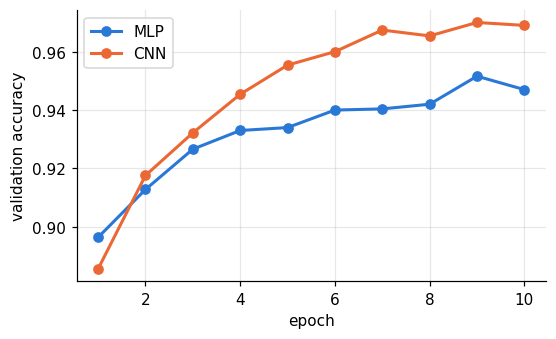

In [10]:
def accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        acc = (model(X).argmax(1) == y).float().mean().item()
    model.train()
    return acc

def train(model, epochs=10, batch_size=64, seed=0):
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    g = torch.Generator().manual_seed(seed)
    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=batch_size, shuffle=True, generator=g)
    val_acc, t0 = [], time.perf_counter()
    for ep in range(epochs):
        model.train()
        for xb, yb in loader:
            loss = F.cross_entropy(model(xb), yb)
            opt.zero_grad(); loss.backward(); opt.step()
        val_acc.append(accuracy(model, X_val, y_val))
    return val_acc, time.perf_counter() - t0

def make_mlp(seed=0):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 10))

mlp, cnn = make_mlp(), make_cnn()
hist, train_seconds, test_acc = {}, {}, {}
for name, model in [("MLP", mlp), ("CNN", cnn)]:
    hist[name], train_seconds[name] = train(model)
    test_acc[name] = accuracy(model, X_test, y_test)
    print(f"{name}: {n_params(model):7,} parameters   val acc {hist[name][-1]:.4f}   test acc {test_acc[name]:.4f}   "
          f"{train_seconds[name] / len(hist[name]):.1f} s per epoch")
check("the CNN beats the MLP on the test set", test_acc["CNN"] > test_acc["MLP"])

fig, ax = plt.subplots(figsize=(5.5, 3.2))
for name in hist: ax.plot(range(1, len(hist[name]) + 1), hist[name], "o-", label=name)
ax.set_xlabel("epoch"); ax.set_ylabel("validation accuracy"); ax.legend(); plt.show()

❓ **Q3.** Compare the two networks: test accuracy, parameters, time per epoch. Compare with the slide "Where we are". The CNN has 12 times fewer parameters: why is it still slower?

**Answer:** Use the measured values printed by the training cell above; they depend on the runtime and hardware, so they should be reported from your own run rather than guessed.

The CNN should be compared with the MLP on three measurements: final test accuracy, number of trainable parameters, and seconds per epoch. The CNN has 9,098 parameters versus the MLP's 109,386 (about 12 times fewer). However, fewer parameters do not automatically mean less computation or faster training. A convolution applies each filter at many spatial positions, across all input channels, and its gradients must also be computed during backpropagation. The CNN additionally processes multi-channel feature maps. Meanwhile, dense layers can use highly optimized matrix-multiplication routines. Therefore, runtime depends on the number and arrangement of operations, memory movement, implementation, and hardware—not parameter count alone.

Record the actual MLP/CNN test accuracies and seconds per epoch from the output when you run this notebook.

## 4 · Look inside
`cnn[0]` is the first convolution: its weights are 8 learned 3 × 3 filters (the slide "Who chooses the filter?"). Blue is negative, red positive.

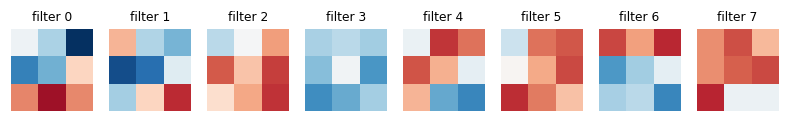

In [11]:
W1 = cnn[0].weight.detach()[:, 0]                    # (8, 3, 3)
lim = W1.abs().max().item()
fig, axes = plt.subplots(1, 8, figsize=(9, 1.5))
for k, ax in enumerate(axes):
    ax.imshow(W1[k], cmap="RdBu_r", vmin=-lim, vmax=lim); ax.set_title(f"filter {k}", fontsize=8); ax.axis("off")
plt.show()

**YOUR TURN 4:** what does the network make of one digit? An `nn.Sequential` can be cut like a list: `cnn[:2]` is the first convolution and its ReLU, `cnn[:3]` adds the max-pool. Compute, for the first test digit, the **feature maps** after the first ReLU, after the first pool, and after the second ReLU.

✓ 8 maps of 28 x 28 after the first ReLU
✓ 8 maps of 14 x 14 after the first pool
✓ 16 maps of 14 x 14 after the second ReLU


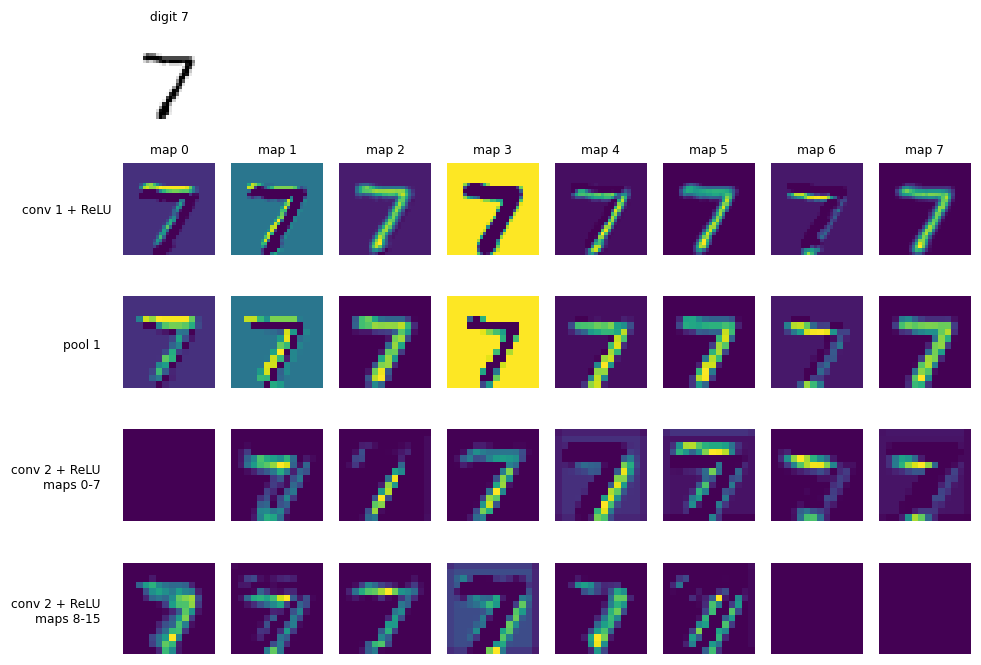

In [12]:
x = X_test[:1]                                       # the first test digit
with torch.no_grad():
    maps1 = cnn[:2](x)       # first convolution + ReLU
    pooled1 = cnn[:3](x)     # first convolution + ReLU + max-pool
    maps2 = cnn[:5](x)       # second convolution + ReLU

check("8 maps of 28 x 28 after the first ReLU", tuple(maps1.shape) == (1, 8, 28, 28))
check("8 maps of 14 x 14 after the first pool", tuple(pooled1.shape) == (1, 8, 14, 14))
check("16 maps of 14 x 14 after the second ReLU", tuple(maps2.shape) == (1, 16, 14, 14) and maps2.min() >= 0,
      "cnn[:5]: conv, ReLU, pool, conv, ReLU (after a ReLU nothing is negative)")

fig, axes = plt.subplots(5, 8, figsize=(9, 6.2))
for ax in axes.flat: ax.axis("off")
axes[0, 0].imshow(x[0, 0].cpu(), cmap="Greys"); axes[0, 0].set_title(f"digit {int(y_test[0])}", fontsize=8)
for k in range(8):
    axes[1, k].imshow(maps1[0, k].cpu(), cmap="viridis"); axes[1, k].set_title(f"map {k}", fontsize=8)
    axes[2, k].imshow(pooled1[0, k].cpu(), cmap="viridis")
    axes[3, k].imshow(maps2[0, k].cpu(), cmap="viridis"); axes[4, k].imshow(maps2[0, k + 8].cpu(), cmap="viridis")
for r, label in [(1, "conv 1 + ReLU"), (2, "pool 1"), (3, "conv 2 + ReLU\nmaps 0-7"), (4, "conv 2 + ReLU\nmaps 8-15")]:
    axes[r, 0].text(-4, 7 if r != 1 else 14, label, ha="right", va="center", fontsize=8)
plt.tight_layout(); plt.show()

❓ **Q4.** Which filters look like edge detectors, and for which direction? Pick one map of the first layer and say which strokes of the digit it lights up. What did pooling do to the maps? Compare with the `\` filter of §1.

**Answer:** The first-layer filters are learned from the training data, so their exact appearance and numbering can differ with initialization and training. Inspect the eight 3 × 3 filters above and identify any that have opposite signs on neighboring pixels; such filters often respond to intensity changes and therefore act like edge or stroke detectors. Describe the direction using the visible positive/negative pattern (for example, a filter may respond strongly to a vertical or diagonal boundary).

In the feature-map figure, choose one first-layer map and compare its bright regions with the corresponding strokes of the input digit. Bright activations indicate locations where that filter responds strongly. Max pooling reduces each 2 × 2 neighborhood to its largest activation, shrinking each map from 28 × 28 to 14 × 14 while retaining strong local responses. This gives some tolerance to small shifts, but discards exact position information. Unlike the hand-designed diagonal filter in §1, these filters are learned automatically by backpropagation.

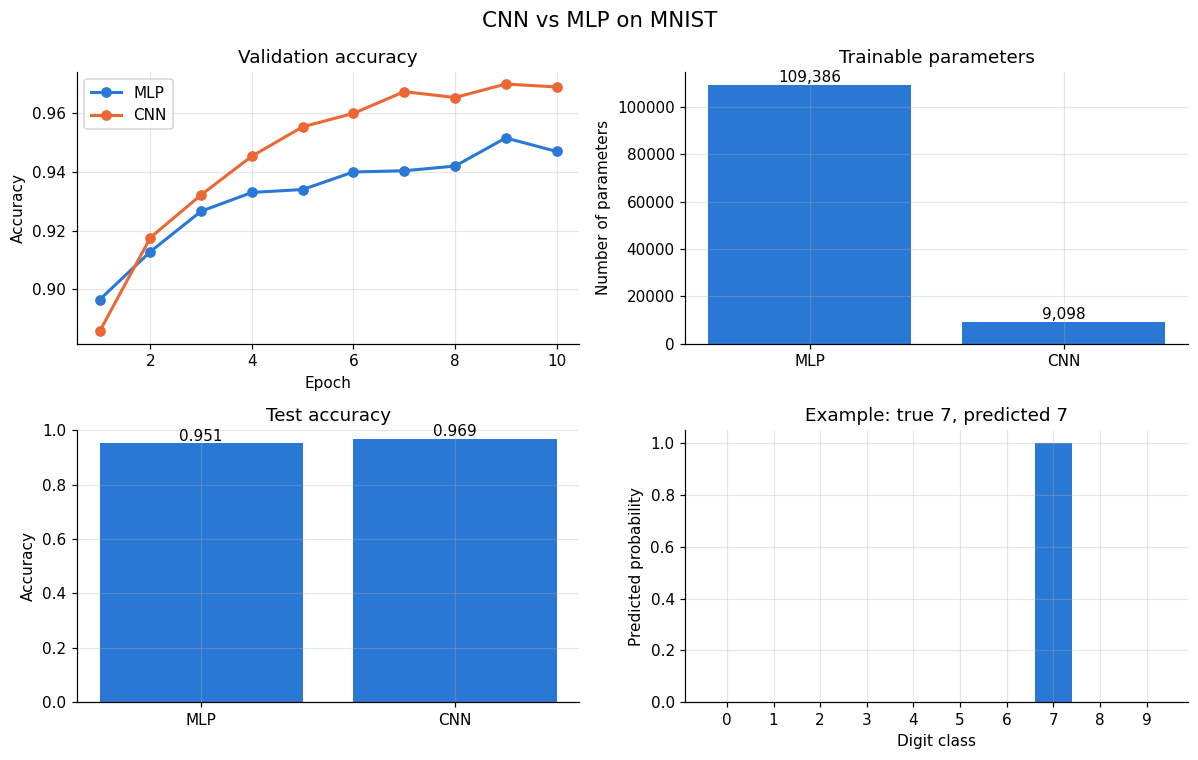

Training time per epoch (seconds):
MLP: 0.64
CNN: 3.52


In [13]:
# A compact summary figure: learning curves, model size, test accuracy, and one prediction.
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

# 1) Validation accuracy over training epochs.
ax = axes[0, 0]
for name in ("MLP", "CNN"):
    ax.plot(range(1, len(hist[name]) + 1), hist[name], marker="o", label=name)
ax.set_title("Validation accuracy")
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy")
ax.legend()

# 2) Trainable parameter counts.
ax = axes[0, 1]
names = ["MLP", "CNN"]
counts = [n_params(mlp), n_params(cnn)]
ax.bar(names, counts)
ax.set_title("Trainable parameters")
ax.set_ylabel("Number of parameters")
for i, value in enumerate(counts):
    ax.text(i, value, f"{value:,}", ha="center", va="bottom")

# 3) Test accuracy measured on the held-out test set.
ax = axes[1, 0]
scores = [test_acc[name] for name in names]
ax.bar(names, scores)
ax.set_title("Test accuracy")
ax.set_ylim(0, 1)
ax.set_ylabel("Accuracy")
for i, value in enumerate(scores):
    ax.text(i, value, f"{value:.3f}", ha="center", va="bottom")

# 4) Show a test example and the CNN's predicted class.
ax = axes[1, 1]
sample = X_test[:1]
with torch.no_grad():
    logits = cnn(sample)
    probabilities = torch.softmax(logits, dim=1)[0].cpu().numpy()
prediction = int(logits.argmax(1).item())
actual = int(y_test[0].item())
ax.bar(np.arange(10), probabilities)
ax.set_xticks(np.arange(10))
ax.set_xlabel("Digit class")
ax.set_ylabel("Predicted probability")
ax.set_title(f"Example: true {actual}, predicted {prediction}")

fig.suptitle("CNN vs MLP on MNIST", fontsize=14)
fig.tight_layout()
plt.show()

print("Training time per epoch (seconds):")
for name in names:
    print(f"{name}: {train_seconds[name] / len(hist[name]):.2f}")